We perform some basic experiments by fitting an ellipse with uniform source-density. 
We assume the source-density is uniform on some interval.  

In [1]:
# First manage the imports
import numpy as np
import matplotlib.pyplot as plt

from bayes_shape_fitting.inference.likelihoods import MarginalLikelihood
from bayes_shape_fitting.inference.posterior import MarginalPosterior
from bayes_shape_fitting.inference.priors import Prior, GaussianPrior, UniformPrior
from bayes_shape_fitting.inference.samplers.map_estimation import MAPOptimizer
from bayes_shape_fitting.visualization.plotting_2d import ShapePlotter2D
from bayes_shape_fitting.inference.noise_functions import IsotropicNoise
from bayes_shape_fitting.inference.source_densitites import UniformSourceDensity
from bayes_shape_fitting.models.shapes.shape_examples import shape_cases
from bayes_shape_fitting.utils.sample_data import simulate_measurement

Importing bayes_shape_fitting.inference
Importing bayes_shape_fitting.models.shapes
Importing bayes_shape_fitting.visualization
Importing bayes_shape_fitting.utils


In [2]:
# let's set a random seed 
np.random.seed(26)

We define an ellipse via a parametrization \gamma: [0,1] \to R^2 (Important: the interval is of the source-parameter is [0,1], not [0, 2 \pi] 

In [3]:
# first we define the shape case

case = shape_cases[1]

shape = case["shape"]
theta = case["theta"]
init_theta = case["init_params"]

In [4]:
# we define a uniform source density
# the parameters are (c,w), where c is the center of the interval and w the (half-)width, so the respectvive interval is [c-w,c+w]
source_density_true = UniformSourceDensity(n_dim = 1, fixed_params=np.array([0.3,0.2]), domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic)  

In [5]:
# the noise function is chosen to be isotropic
noise_function_true = IsotropicNoise(dim_param=shape.parameter_dim, dim_ambient=shape.ambient_dim, fixed_params=0.1)

In [6]:
# simulate a measurement of 100 points
measurement = simulate_measurement(shape, theta, source_density_true, noise_function_true, num_samples=100)

In [7]:
# for formulating a posterior, we need to define likelihood and prior
# we choose again a Uniform as source density

noise_function = IsotropicNoise(dim_param=shape.parameter_dim, dim_ambient=shape.ambient_dim)
source_density = UniformSourceDensity(n_dim = 1, domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic)  

In [8]:
# then the likelihood 
likelihood = MarginalLikelihood(shape=shape, source_density=source_density, noise_function=noise_function)

In [9]:
# let's also define a prior on the Source density
mean = np.array([0.3,0.2])  # the first parameter resembles the interval center c, and the second the half-width w
cov =  np.diag([1,0.0001])  # we set a prior independently on those
source_prior = GaussianPrior(mean=mean, cov=cov)
source_density.prior = source_prior

In [10]:
# and let's define a prior on the noise function (on sigma)
mean = np.array([0.1]) 
cov =  np.diag([0.000001])  
noise_prior = GaussianPrior(mean=mean, cov=cov)
noise_function.prior = noise_prior

In [11]:
# and the posterior
posterior = MarginalPosterior(shape=shape, measurement=measurement, likelihood=likelihood)

In [12]:
# now we define the optimizer
#optimizer = MAPOptimizer(method='Powell', verbose=True, ftol = 1e-6, gtol = 1e-4)
optimizer = MAPOptimizer(method='L-BFGS-B', verbose=True, ftol = 1e-6, gtol = 1e-4)

In [13]:
# let us define an initial guess for the source-densitiy
init_source_density = np.array([0.4, 0.1]) # interval_center, half-width
init_noise = np.array([0.15])

In [14]:
# perform the MAP estimation
# we set the bounds reasonable
source_bounds = [(0,1),(0.05,0.4)]
noise_bounds = [(0.05,0.2)]
result = optimizer.optimize(posterior, shape_init=init_theta, source_init=init_source_density, noise_init=init_noise,source_bounds=source_bounds, noise_bounds=noise_bounds)

MAP Optimization with L-BFGS-B
Initial log posterior: -2783.952744
Optimizing blocks: shape source noise
Number of optimized parameters: 8
Using box constraints: 8 bounds


Optimization Complete
Success: False
Message: ABNORMAL: 
Final log posterior: -269.454774
Improvement: 2514.497970
Iterations: 44
Function evaluations: 1305
Runtime: 1.306s
----------------------------------------------------------------------
⚠ Abnormal termination detected
• Optimizer reported failure (status=2): ABNORMAL:
• First-order optimality not satisfied: ||g||_inf=2.681e+01 > tol=1.000e-04
Gradient infinity-norm: 2.681e+01



(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Source Density Function'}, xlabel='Parameter t', ylabel='Density'>)

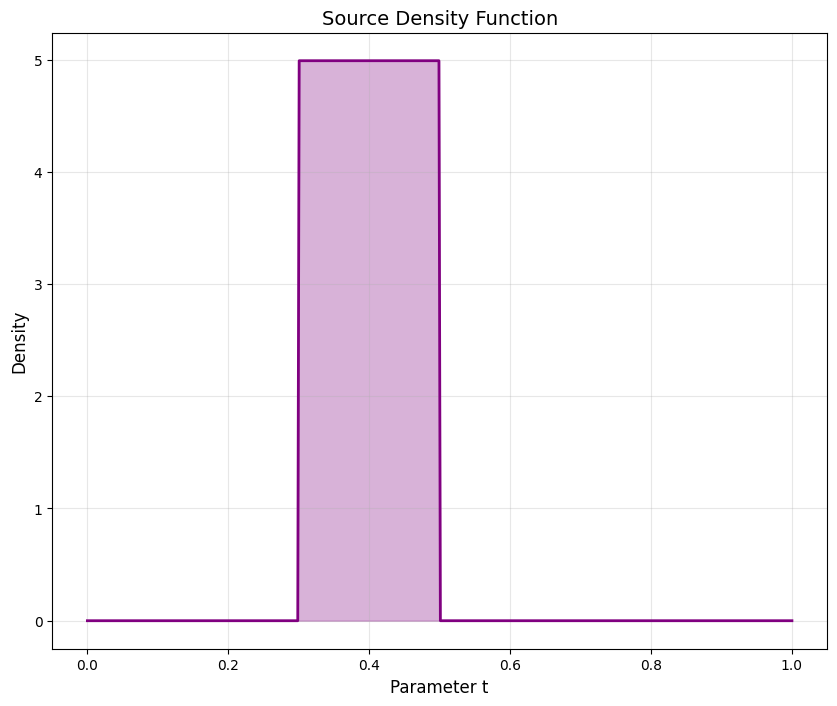

In [15]:
# Let's define a plotter and plot the initial source_density
plotter = ShapePlotter2D()
plotter.plot_source_density(shape, source_density, params=init_source_density)

So in total, we our posterior has 8 parameters, 5 for the ellipse (c_x,c_y,a,b, \phi), 2 for the source-density (c,w) and \sigma for the noise function
There is no prior on the shape parameters but a Gaussian prior on (c,w) and a Gaussian prior on \sigma
We perform MAP-estimation on all 7 of them. 

In [16]:
theta_map = result.theta_map[0:shape.get_n_params()]

(<Figure size 1000x800 with 1 Axes>, <Axes: >)

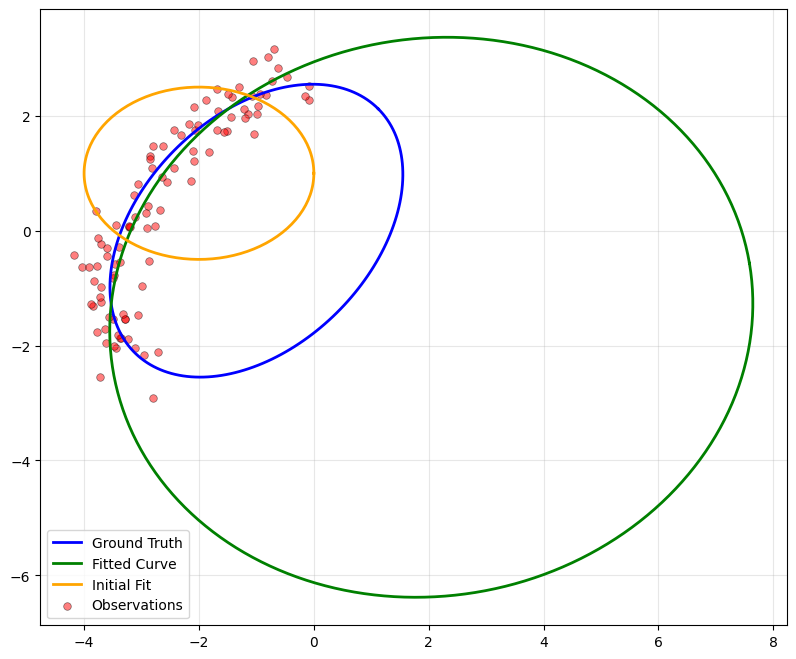

In [17]:
# we plot the result of the fit
fig, ax, _ = plotter.plot_shape(shape, theta, label="Ground Truth")
plotter.plot_shape(shape, theta_map, ax=ax, label="Fitted Curve", color="green")
plotter.plot_shape(shape, init_theta, ax=ax, label="Initial Fit", color="orange")
plotter.plot_observations(observations=measurement, ax=ax)

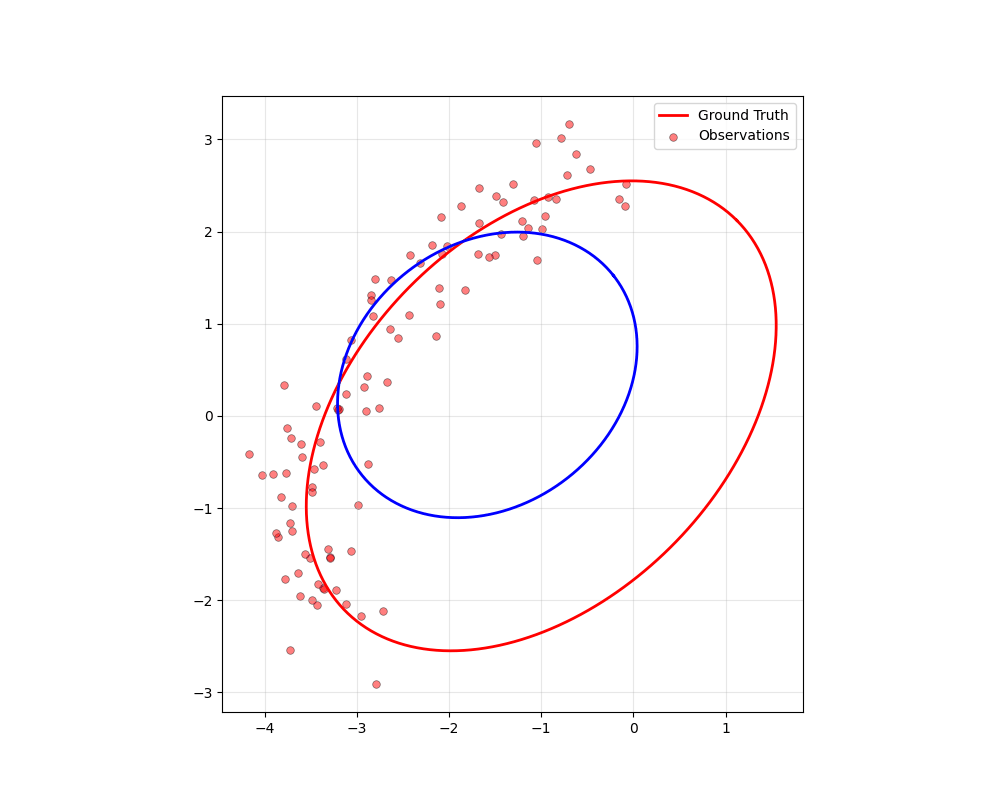

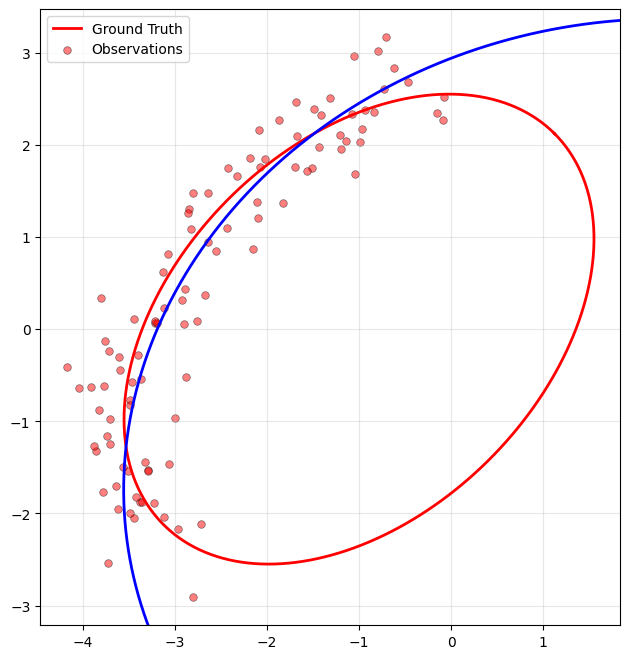

In [18]:
# let's do the animation
from bayes_shape_fitting.visualization.animation_2d import ShapePlotterAnimations

animator = ShapePlotterAnimations()
# we need to crop the param_history to only get the shape values
param_history = [r[:5] for r in result.param_history]

# first plot the real shape
fig, ax, _ = plotter.plot_shape(shape, theta, label="Ground Truth", color = "red")
plotter.plot_observations(observations=measurement, ax=ax)
ani = animator.animate_param_history(shape, param_history, ax = ax)
ani.save("my_animation.gif", writer="pillow", fps=5)
from IPython.display import Image
Image("my_animation.gif")

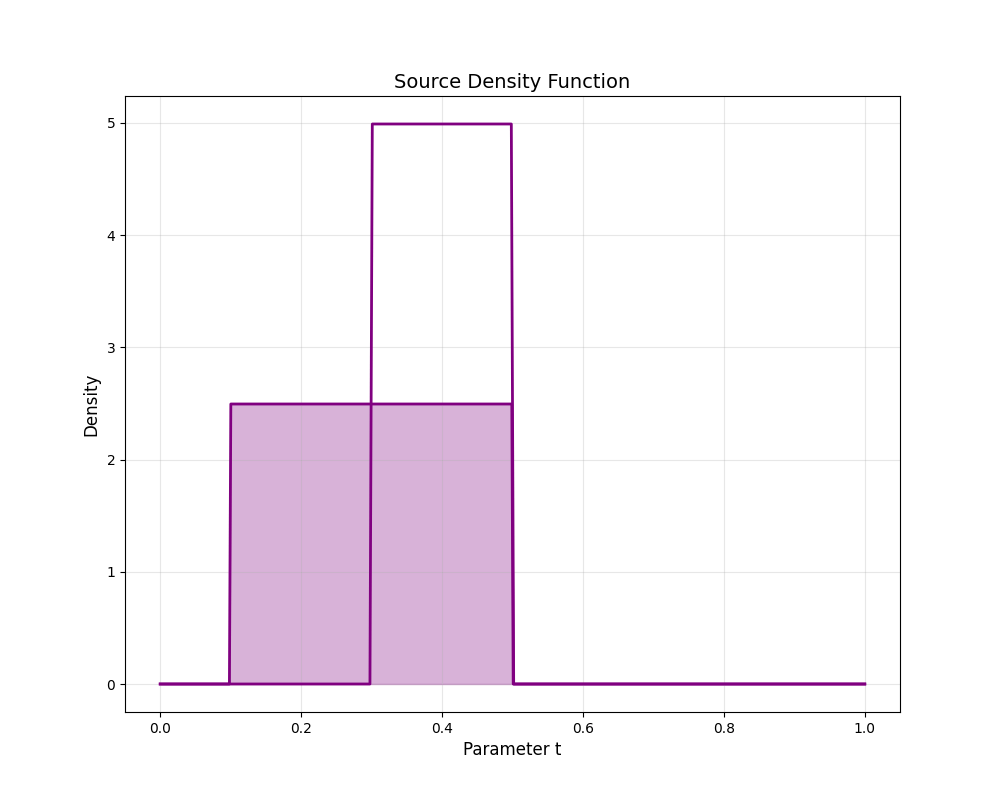

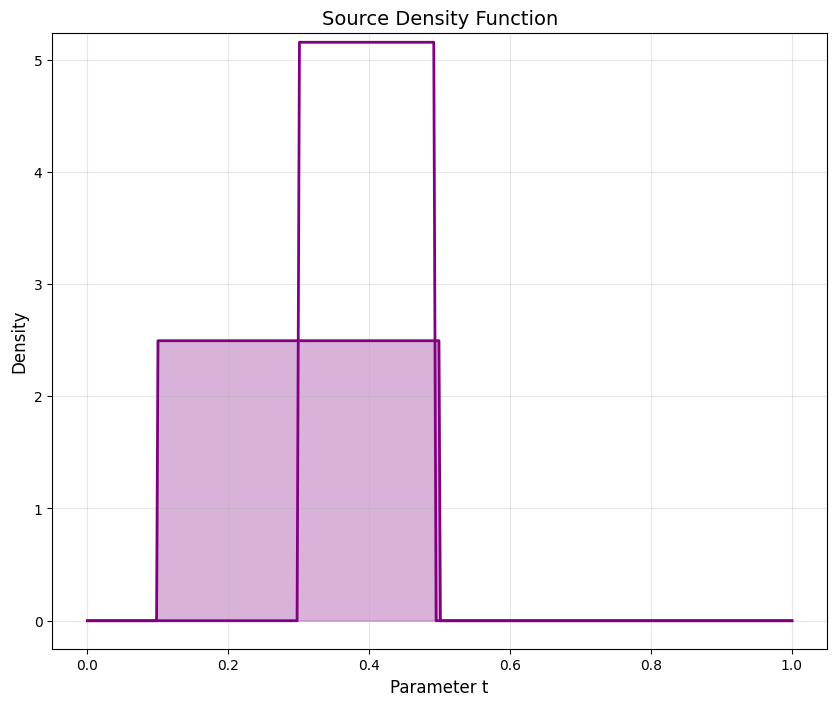

In [19]:
# let's also animate the source_density

source_params_history = [r[5:7] for r in result.param_history]

plotter.plot_source_density(shape, source_density, params=source_density_true.fixed_params)

ani_source = animator.animate_source_density(shape, source_density, source_params_history)
ani_source.save("Source_density_animation.gif", writer="pillow", fps=5)
Image("Source_density_animation.gif")

In [20]:
result.param_history

[array([-1.58479402,  0.44422063,  1.74223612,  1.41664661,  0.66732543,
         0.39993253,  0.10020232,  0.14993256]),
 array([-1.59063384,  0.4520376 ,  1.74586153,  1.41781896,  0.65793958,
         0.39993348,  0.10020092,  0.14993342]),
 array([-1.56713703,  0.48610185,  1.77052163,  1.41342   ,  0.57097877,
         0.39992282,  0.09952882,  0.10753725]),
 array([-1.57615452,  0.50081574,  1.77774593,  1.41526903,  0.55140931,
         0.39992403,  0.09951634,  0.10693221]),
 array([-1.53748873,  0.49612043,  1.78306323,  1.40847593,  0.52274912,
         0.39991332,  0.09948223,  0.10523246]),
 array([-1.28047996,  0.43949156,  1.80311755,  1.36313051,  0.38076802,
         0.39984453,  0.09938834,  0.10194865]),
 array([-1.15194991,  0.38764361,  1.80191264,  1.34149022,  0.35292714,
         0.39981133,  0.09940666,  0.10401114]),
 array([-1.10629533,  0.36501089,  1.80134762,  1.33480698,  0.34960229,
         0.3997992 ,  0.09944264,  0.10657769]),
 array([-1.10225284,  0.

In [21]:
noise_function_true.evaluate([0.1])

array([[[0.1, 0. ],
        [0. , 0.1]]])